In [2]:
!unzip Hrithik-Vs-Bradly.zip -d /content/Hrithik-Vs-Bradly


Archive:  Hrithik-Vs-Bradly.zip
   creating: /content/Hrithik-Vs-Bradly/Hrithik-Vs-Bradly/
  inflating: /content/Hrithik-Vs-Bradly/Hrithik-Vs-Bradly/.DS_Store  
  inflating: /content/Hrithik-Vs-Bradly/__MACOSX/Hrithik-Vs-Bradly/._.DS_Store  
   creating: /content/Hrithik-Vs-Bradly/Hrithik-Vs-Bradly/Bradly/
   creating: /content/Hrithik-Vs-Bradly/Hrithik-Vs-Bradly/Hritik/
  inflating: /content/Hrithik-Vs-Bradly/Hrithik-Vs-Bradly/Bradly/B3.jpeg  
  inflating: /content/Hrithik-Vs-Bradly/__MACOSX/Hrithik-Vs-Bradly/Bradly/._B3.jpeg  
  inflating: /content/Hrithik-Vs-Bradly/Hrithik-Vs-Bradly/Bradly/B2.jpeg  
  inflating: /content/Hrithik-Vs-Bradly/__MACOSX/Hrithik-Vs-Bradly/Bradly/._B2.jpeg  
  inflating: /content/Hrithik-Vs-Bradly/Hrithik-Vs-Bradly/Bradly/B9.jpeg  
  inflating: /content/Hrithik-Vs-Bradly/__MACOSX/Hrithik-Vs-Bradly/Bradly/._B9.jpeg  
  inflating: /content/Hrithik-Vs-Bradly/Hrithik-Vs-Bradly/Bradly/B5.jpeg  
  inflating: /content/Hrithik-Vs-Bradly/__MACOSX/Hrithik-Vs-Bradly/B

In [4]:
import os
import pandas as pd
import numpy as np
from PIL import Image

base_dir = '/content/Hrithik-Vs-Bradly/Hrithik-Vs-Bradly'
categories = ['Bradly', 'Hritik']
img_size = (128, 128)

data = []
labels = []
filenames = []

# Load and prepare the images
for label_idx, category in enumerate(categories):
    category_path = os.path.join(base_dir, category)
    if not os.path.exists(category_path):
        continue
    for img_name in os.listdir(category_path):
        if img_name.startswith('.'):
            continue
        img_path = os.path.join(category_path, img_name)
        try:
            img = Image.open(img_path).convert('RGB')
            img_resized = img.resize(img_size)
            # Convert image to flat array for traditional machine learning processing
            img_flat = np.array(img_resized).flatten()
            data.append(img_flat)
            labels.append(category)
            filenames.append(img_name)
        except Exception as e:
            print(f"Could not load {img_path}: {e}")

# Create a structured DataFrame representation
features_df = pd.DataFrame(data)
features_df['label'] = labels
features_df['filename'] = filenames

print(f"Loaded {len(features_df)} images successfully.")
display(features_df.head())

Loaded 20 images successfully.


,0,1,2,3,4,5,6,7,8,9,...,49144,49145,49146,49147,49148,49149,49150,49151,label,filename
0,78,84,98,78,84,98,77,83,97,75,...,179,198,176,184,202,185,193,211,Bradly,B9.jpeg
1,216,188,166,216,188,166,217,189,167,219,...,0,0,0,0,0,0,0,0,Bradly,B3.jpeg
2,220,211,194,241,232,215,238,229,212,208,...,245,237,248,248,240,248,247,243,Bradly,B10.jpeg
3,40,49,44,41,50,45,41,50,45,43,...,128,116,111,127,114,109,125,112,Bradly,B8.jpeg
4,157,153,141,153,150,136,149,148,133,149,...,61,92,51,60,91,51,60,91,Bradly,B5.jpeg


In [7]:
import cv2
import matplotlib.pyplot as plt

# Let's select one representative image from the Bradly folder to demonstrate the filters
sample_img_path = os.path.join(base_dir, 'Bradly', 'B9.jpeg')

# Read the original image using OpenCV
original_bgr = cv2.imread(sample_img_path)
original_rgb = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)

# 1. Grayscale Filter
gray_img = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2GRAY)

# 2. Gaussian Blur Filter
blurred_img = cv2.GaussianBlur(gray_img, (15, 15), 0)

# 3. Sobel Filter (Edge Detection)
sobel_x = cv2.Sobel(gray_img, cv2.CV_64F, 1, 0, ksize=5)
sobel_y = cv2.Sobel(gray_img, cv2.CV_64F, 0, 1, ksize=5)
sobel_combined = cv2.magnitude(sobel_x, sobel_y)

# 4. Canny Edge Detection
canny_edges = cv2.Canny(gray_img, 100, 200)


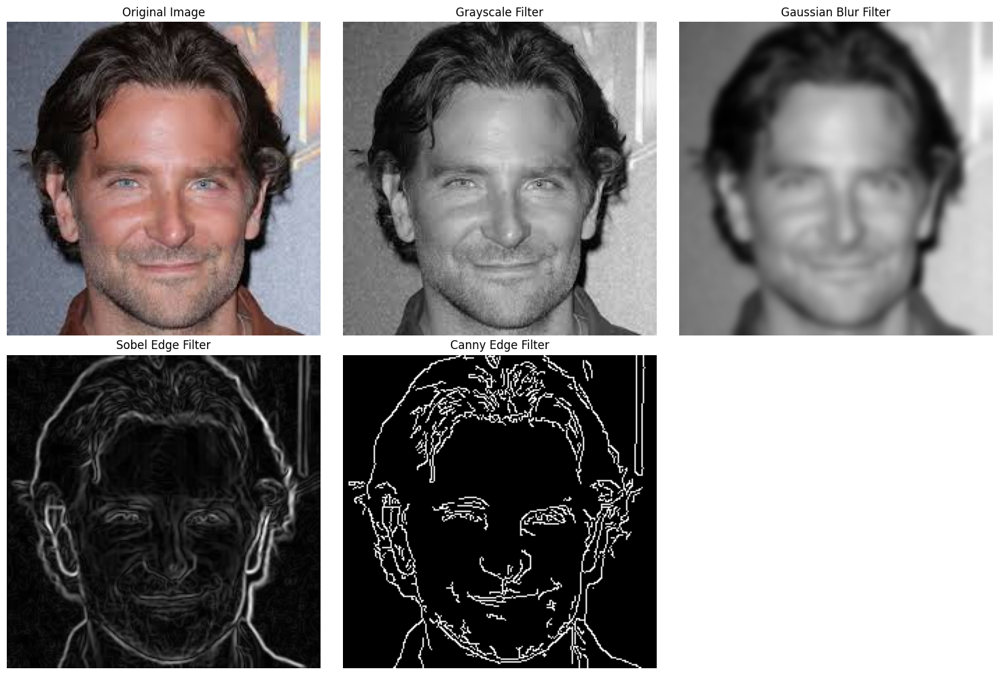

In [8]:
# Plot and visualize each filter output
plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.imshow(original_rgb)
plt.title("Original Image")
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(gray_img, cmap='gray')
plt.title("Grayscale Filter")
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(blurred_img, cmap='gray')
plt.title("Gaussian Blur Filter")
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(sobel_combined, cmap='gray')
plt.title("Sobel Edge Filter")
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(canny_edges, cmap='gray')
plt.title("Canny Edge Filter")
plt.axis('off')

plt.tight_layout()
plt.show()

In [9]:
# 1. Bilateral Filter (smoothens while preserving edges)
bilateral_img = cv2.bilateralFilter(original_rgb, d=9, sigmaColor=75, sigmaSpace=75)

# 2. Sobel Edge Detection (re-applying Sobel on grayscale)
gray = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2GRAY)
sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
sobel_magnitude = cv2.magnitude(sobelx, sobely)

# 3. Laplacian Filter (second-order derivative for edge detection)
laplacian_img = cv2.Laplacian(gray, cv2.CV_64F, ksize=3)
laplacian_abs = np.uint8(np.absolute(laplacian_img))


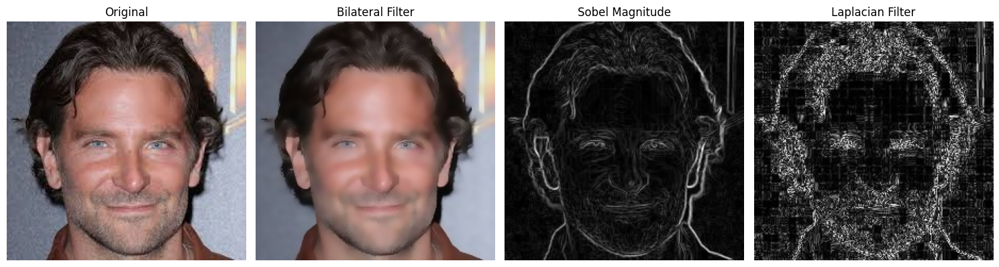

In [10]:
# Visualize Bilateral, Sobel, and Laplacian filters
plt.figure(figsize=(15, 5))

plt.subplot(1, 4, 1)
plt.imshow(original_rgb)
plt.title("Original")
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(bilateral_img)
plt.title("Bilateral Filter")
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(sobel_magnitude, cmap='gray')
plt.title("Sobel Magnitude")
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(laplacian_abs, cmap='gray')
plt.title("Laplacian Filter")
plt.axis('off')

plt.tight_layout()
plt.show()

In [19]:
# Load a sample image of Hrithik
sample_img_path_hritik = os.path.join(base_dir, 'Hritik', 'H4.jpeg')
original_bgr_h = cv2.imread(sample_img_path_hritik)
original_rgb_h = cv2.cvtColor(original_bgr_h, cv2.COLOR_BGR2RGB)

# 1. Bilateral Filter on Hrithik's image
bilateral_img_h = cv2.bilateralFilter(original_rgb_h, d=9, sigmaColor=75, sigmaSpace=75)

# 2. Sobel Edge Detection on Hrithik's image
gray_h = cv2.cvtColor(original_bgr_h, cv2.COLOR_BGR2GRAY)
sobelx_h = cv2.Sobel(gray_h, cv2.CV_64F, 1, 0, ksize=3)
sobely_h = cv2.Sobel(gray_h, cv2.CV_64F, 0, 1, ksize=3)
sobel_magnitude_h = cv2.magnitude(sobelx_h, sobely_h)

# 3. Laplacian Filter on Hrithik's image
laplacian_img_h = cv2.Laplacian(gray_h, cv2.CV_64F, ksize=3)
laplacian_abs_h = np.uint8(np.absolute(laplacian_img_h))


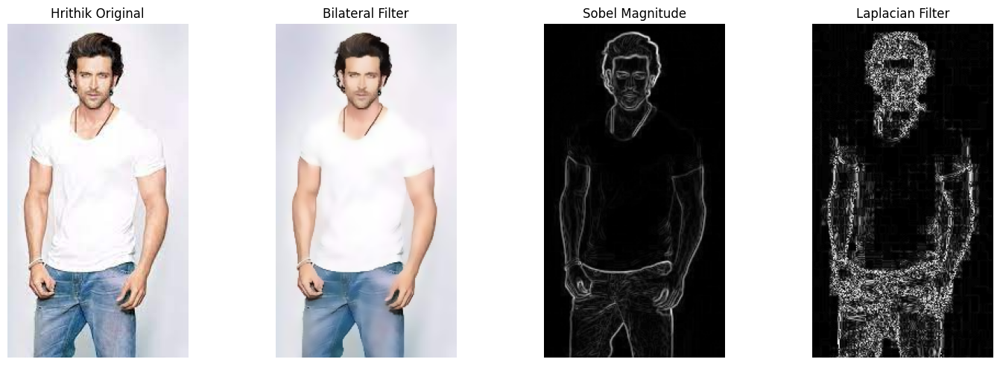

In [20]:
# Visualize Bilateral, Sobel, and Laplacian filters for Hrithik
plt.figure(figsize=(15, 5))

plt.subplot(1, 4, 1)
plt.imshow(original_rgb_h)
plt.title("Hrithik Original")
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(bilateral_img_h)
plt.title("Bilateral Filter")
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(sobel_magnitude_h, cmap='gray')
plt.title("Sobel Magnitude")
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(laplacian_abs_h, cmap='gray')
plt.title("Laplacian Filter")
plt.axis('off')

plt.tight_layout()
plt.show()

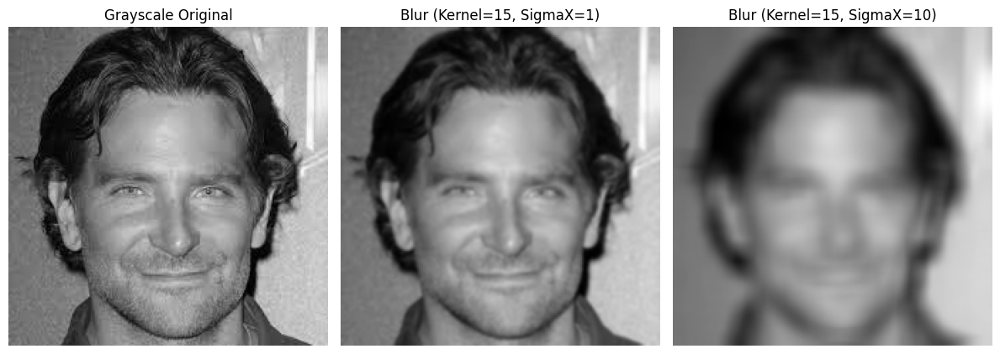

In [14]:
# Demonstration of varying sigmaX and sigmaY values on Bradly's image

# Large kernel, small sigmaX (forces standard deviation to be small despite large kernel size)
blur_low_sigma = cv2.GaussianBlur(gray_img, (15, 15), sigmaX=1)

# Large kernel, large sigmaX (increases blur/spread)
blur_high_sigma = cv2.GaussianBlur(gray_img, (15, 15), sigmaX=20)

# Plotting the comparisons
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray_img, cmap='gray')
plt.title("Grayscale Original")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(blur_low_sigma, cmap='gray')
plt.title("Blur (Kernel=15, SigmaX=1)")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(blur_high_sigma, cmap='gray')
plt.title("Blur (Kernel=15, SigmaX=10)")
plt.axis('off')

plt.tight_layout()
plt.show()

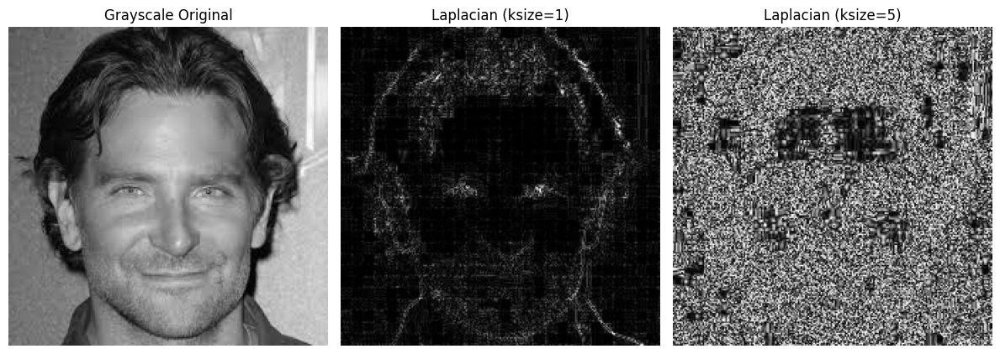

In [17]:
# Demonstration of varying kernel sizes for the Laplacian filter

# Laplacian with a small kernel size (ksize = 1)
laplacian_k1 = cv2.Laplacian(gray, cv2.CV_64F, ksize=1)
laplacian_k1_abs = np.uint8(np.absolute(laplacian_k1))

# Laplacian with a larger kernel size (ksize = 5)
laplacian_k5 = cv2.Laplacian(gray, cv2.CV_64F, ksize=5)
laplacian_k5_abs = np.uint8(np.absolute(laplacian_k5))

# Plotting the comparisons
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray, cmap='gray')
plt.title("Grayscale Original")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(laplacian_k1_abs, cmap='gray')
plt.title("Laplacian (ksize=1)")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(laplacian_k5_abs, cmap='gray')
plt.title("Laplacian (ksize=5)")
plt.axis('off')

plt.tight_layout()
plt.show()

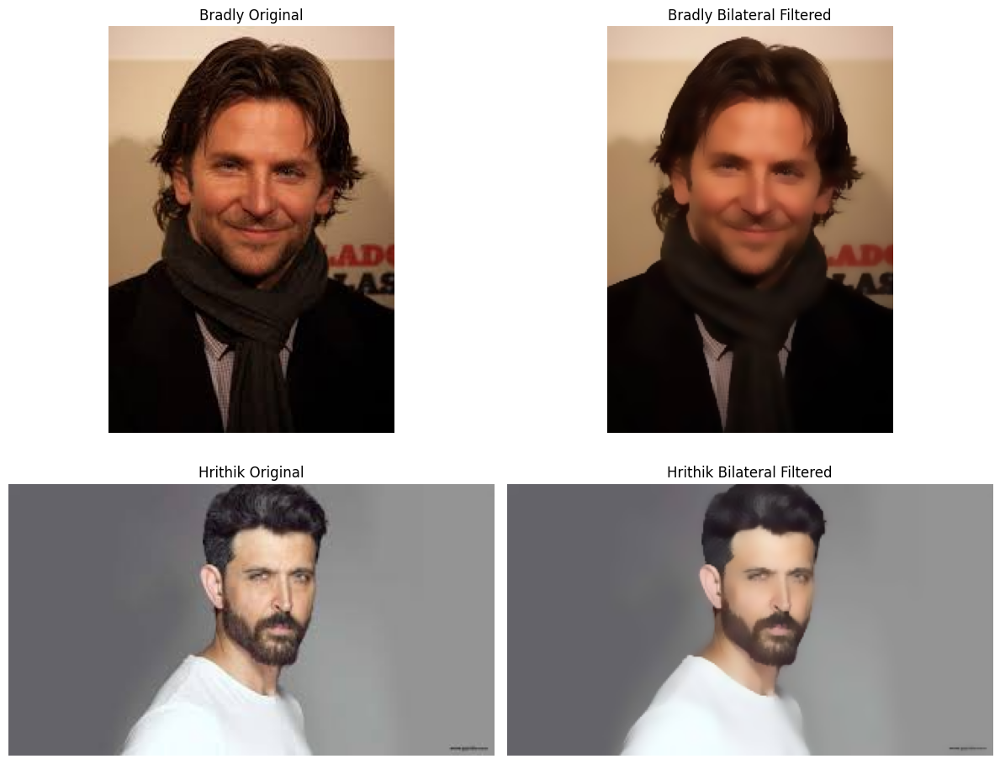

In [21]:
# Compare Bilateral Filter smoothing effects across both subjects

# Re-loading/reading both original images in RGB
img_bradly = cv2.cvtColor(cv2.imread(os.path.join(base_dir, 'Bradly', 'B3.jpeg')), cv2.COLOR_BGR2RGB)
img_hritik = cv2.cvtColor(cv2.imread(os.path.join(base_dir, 'Hritik', 'H9.jpeg')), cv2.COLOR_BGR2RGB)

# Apply Bilateral Filter with same parameters to both
d, sigmaColor, sigmaSpace = 9, 75, 75
bilateral_bradly = cv2.bilateralFilter(img_bradly, d, sigmaColor, sigmaSpace)
bilateral_hritik = cv2.bilateralFilter(img_hritik, d, sigmaColor, sigmaSpace)

# Plot the comparison
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Bradly row
axes[0, 0].imshow(img_bradly)
axes[0, 0].set_title("Bradly Original")
axes[0, 0].axis('off')

axes[0, 1].imshow(bilateral_bradly)
axes[0, 1].set_title("Bradly Bilateral Filtered")
axes[0, 1].axis('off')

# Hrithik row
axes[1, 0].imshow(img_hritik)
axes[1, 0].set_title("Hrithik Original")
axes[1, 0].axis('off')

axes[1, 1].imshow(bilateral_hritik)
axes[1, 1].set_title("Hrithik Bilateral Filtered")
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

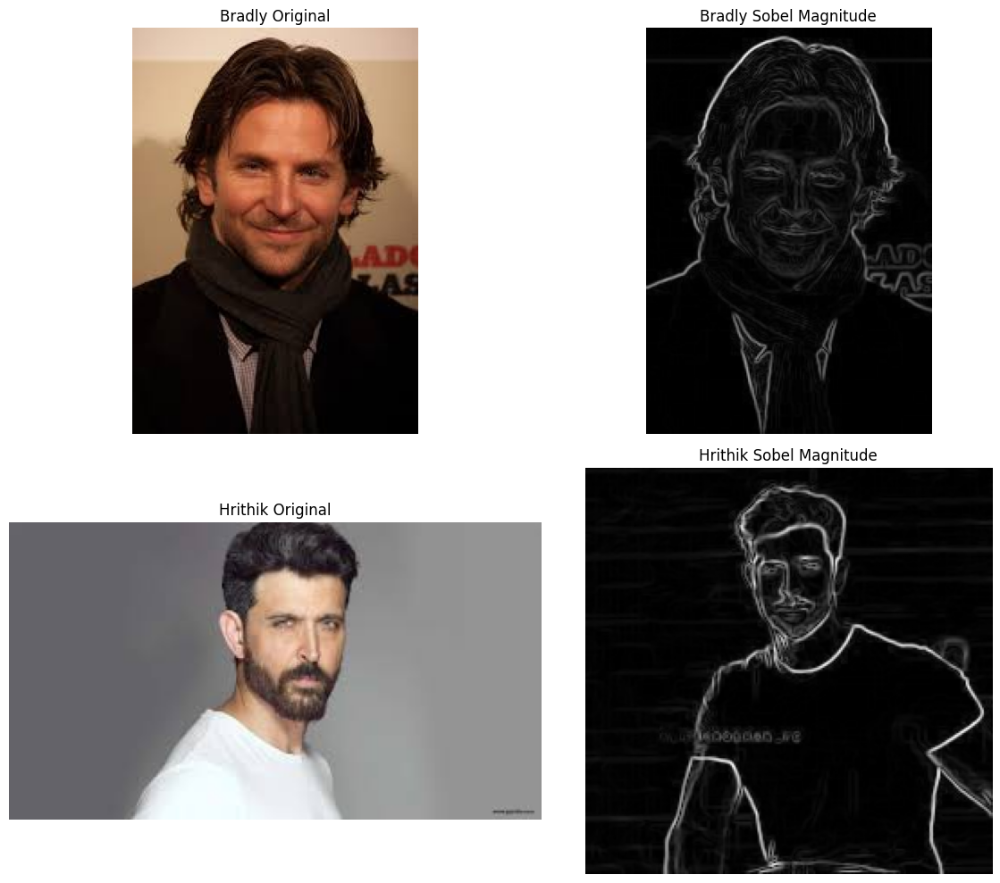

In [26]:
# Compare Sobel Edge Detection effects across both subjects

# Compute Sobel Magnitude for Bradly's image
gray_bradly = cv2.cvtColor(cv2.imread(os.path.join(base_dir, 'Bradly', 'B3.jpeg')), cv2.COLOR_BGR2GRAY)
sobel_x_b = cv2.Sobel(gray_bradly, cv2.CV_64F, 1, 0, ksize=3)
sobel_y_b = cv2.Sobel(gray_bradly, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag_bradly = cv2.magnitude(sobel_x_b, sobel_y_b)

# Compute Sobel Magnitude for Hrithik's image (changing H1.jpeg to H1.webp)
gray_hritik = cv2.cvtColor(cv2.imread(os.path.join(base_dir, 'Hritik', 'H1.webp')), cv2.COLOR_BGR2GRAY)
sobel_x_h = cv2.Sobel(gray_hritik, cv2.CV_64F, 1, 0, ksize=3)
sobel_y_h = cv2.Sobel(gray_hritik, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag_hritik = cv2.magnitude(sobel_x_h, sobel_y_h)

# Plot the comparison side-by-side
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Bradly Row
axes[0, 0].imshow(img_bradly)
axes[0, 0].set_title("Bradly Original")
axes[0, 0].axis('off')

axes[0, 1].imshow(sobel_mag_bradly, cmap='gray')
axes[0, 1].set_title("Bradly Sobel Magnitude")
axes[0, 1].axis('off')

# Hrithik Row
axes[1, 0].imshow(img_hritik)
axes[1, 0].set_title("Hrithik Original")
axes[1, 0].axis('off')

axes[1, 1].imshow(sobel_mag_hritik, cmap='gray')
axes[1, 1].set_title("Hrithik Sobel Magnitude")
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

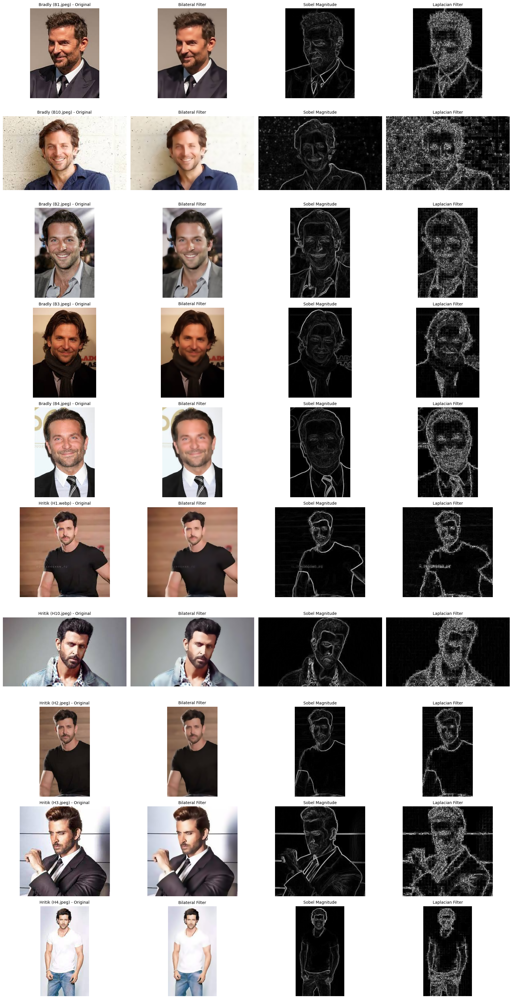

In [33]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Select 5 Bradly and 5 Hritik filenames
base_dir = '/content/Hrithik-Vs-Bradly/Hrithik-Vs-Bradly'
bradly_dir = os.path.join(base_dir, 'Bradly')
hritik_dir = os.path.join(base_dir, 'Hritik')

# Filter out hidden system files starting with '.'
bradly_files = sorted([f for f in os.listdir(bradly_dir) if not f.startswith('.')])[:5]
hritik_files = sorted([f for f in os.listdir(hritik_dir) if not f.startswith('.')])[:5]

target_images = []
for f in bradly_files:
    target_images.append((os.path.join(bradly_dir, f), 'Bradly', f))
for f in hritik_files:
    target_images.append((os.path.join(hritik_dir, f), 'Hritik', f))

# 2. Plotting the 10 images with their respective filters side-by-side (10 rows, 4 columns)
fig, axes = plt.subplots(10, 4, figsize=(18, 35))

for idx, (img_path, category, filename) in enumerate(target_images):
    # Load image
    img_bgr = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # Apply Bilateral Filter
    bilateral = cv2.bilateralFilter(img_rgb, d=9, sigmaColor=75, sigmaSpace=75)

    # Apply Sobel Filter
    sobelx = cv2.Sobel(img_gray, cv2.CV_64F, 1, 0, ksize=3)
    sobely = cv2.Sobel(img_gray, cv2.CV_64F, 0, 1, ksize=3)
    sobel_magnitude = cv2.magnitude(sobelx, sobely)

    # Apply Laplacian Filter
    laplacian = cv2.Laplacian(img_gray, cv2.CV_64F, ksize=3)
    laplacian_abs = np.uint8(np.absolute(laplacian))

    # Plot Column 1: Original
    axes[idx, 0].imshow(img_rgb)
    axes[idx, 0].set_title(f"{category} ({filename}) - Original", fontsize=10)
    axes[idx, 0].axis('off')

    # Plot Column 2: Bilateral
    axes[idx, 1].imshow(bilateral)
    axes[idx, 1].set_title("Bilateral Filter", fontsize=10)
    axes[idx, 1].axis('off')

    # Plot Column 3: Sobel Magnitude
    axes[idx, 2].imshow(sobel_magnitude, cmap='gray')
    axes[idx, 2].set_title("Sobel Magnitude", fontsize=10)
    axes[idx, 2].axis('off')

    # Plot Column 4: Laplacian
    axes[idx, 3].imshow(laplacian_abs, cmap='gray')
    axes[idx, 3].set_title("Laplacian Filter", fontsize=10)
    axes[idx, 3].axis('off')

plt.tight_layout()
plt.show()

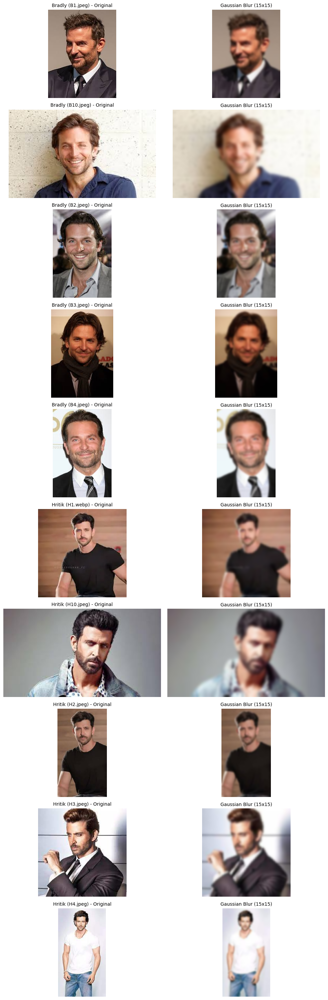

In [34]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Select 5 Bradly and 5 Hritik filenames
base_dir = '/content/Hrithik-Vs-Bradly/Hrithik-Vs-Bradly'
bradly_dir = os.path.join(base_dir, 'Bradly')
hritik_dir = os.path.join(base_dir, 'Hritik')

# Filter out hidden system files starting with '.'
bradly_files = sorted([f for f in os.listdir(bradly_dir) if not f.startswith('.')])[:5]
hritik_files = sorted([f for f in os.listdir(hritik_dir) if not f.startswith('.')])[:5]

target_images = []
for f in bradly_files:
    target_images.append((os.path.join(bradly_dir, f), 'Bradly', f))
for f in hritik_files:
    target_images.append((os.path.join(hritik_dir, f), 'Hritik', f))

# 2. Plotting the 10 images with Gaussian blur side-by-side (10 rows, 2 columns)
fig, axes = plt.subplots(10, 2, figsize=(10, 30))

for idx, (img_path, category, filename) in enumerate(target_images):
    # Load image
    img_bgr = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # Apply Gaussian Blur (using a 15x15 kernel to clearly see the smoothing effect)
    blurred = cv2.GaussianBlur(img_rgb, (15, 15), 0)

    # Plot Column 1: Original
    axes[idx, 0].imshow(img_rgb)
    axes[idx, 0].set_title(f"{category} ({filename}) - Original", fontsize=10)
    axes[idx, 0].axis('off')

    # Plot Column 2: Gaussian Blur
    axes[idx, 1].imshow(blurred)
    axes[idx, 1].set_title("Gaussian Blur (15x15)", fontsize=10)
    axes[idx, 1].axis('off')

plt.tight_layout()
plt.show()

KNN Model Accuracy: 60.00%

Classification Report:
              precision    recall  f1-score   support

      Bradly       1.00      0.33      0.50         3
      Hritik       0.50      1.00      0.67         2

    accuracy                           0.60         5
   macro avg       0.75      0.67      0.58         5
weighted avg       0.80      0.60      0.57         5



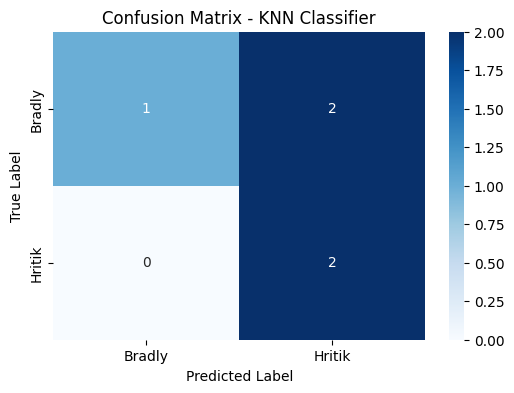

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns

# 1. Prepare Features (X) and Labels (y)
# We drop 'label' and 'filename' columns to isolate pixel intensity values
X = features_df.drop(columns=['label', 'filename']).values
y = features_df['label'].values

# 2. Split the dataset into Training and Testing sets (e.g., 75% train, 25% test)
# Stratify ensures a balanced class split in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# 3. Initialize and train the KNN Classifier
# Setting n_neighbors=3 as a baseline for this small dataset
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

# 4. Predict on the test set
y_pred = knn.predict(X_test)

# 5. Evaluate the model performance
accuracy = accuracy_score(y_test, y_pred)
print(f"KNN Model Accuracy: {accuracy * 100:.2f}%\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

# 6. Plot the Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=categories)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=categories, yticklabels=categories, cmap='Blues')
plt.title('Confusion Matrix - KNN Classifier')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

Neighbors: 1 -> Train Accuracy: 100.0%, Test Accuracy: 60.0%
Neighbors: 2 -> Train Accuracy: 80.0%, Test Accuracy: 80.0%
Neighbors: 3 -> Train Accuracy: 80.0%, Test Accuracy: 60.0%
Neighbors: 4 -> Train Accuracy: 60.0%, Test Accuracy: 40.0%
Neighbors: 5 -> Train Accuracy: 53.3%, Test Accuracy: 60.0%
Neighbors: 6 -> Train Accuracy: 60.0%, Test Accuracy: 80.0%
Neighbors: 7 -> Train Accuracy: 53.3%, Test Accuracy: 20.0%


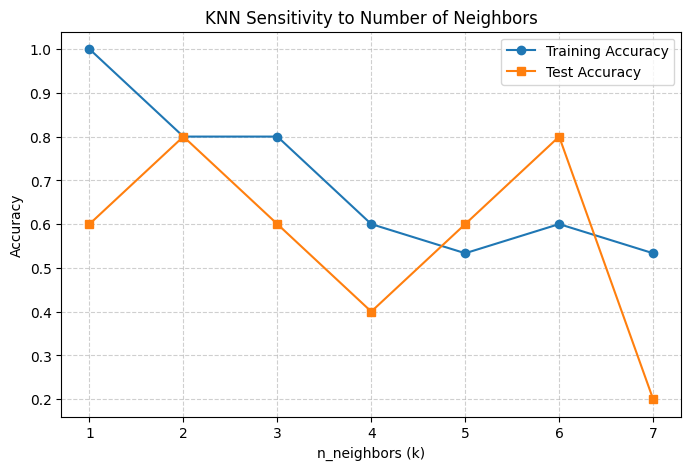

In [28]:
# Evaluate KNN model performance with varying number of neighbors

neighbor_settings = range(1, 8)
test_accuracies = []
train_accuracies = []

for k in neighbor_settings:
    # Build the model
    clf = KNeighborsClassifier(n_neighbors=k)
    clf.fit(X_train, y_train)

    # Record training set accuracy
    train_acc = clf.score(X_train, y_train)
    train_accuracies.append(train_acc)

    # Record generalization accuracy
    test_acc = clf.score(X_test, y_test)
    test_accuracies.append(test_acc)

    print(f"Neighbors: {k} -> Train Accuracy: {train_acc*100:.1f}%, Test Accuracy: {test_acc*100:.1f}%")

# Plot the results
plt.figure(figsize=(8, 5))
plt.plot(neighbor_settings, train_accuracies, label="Training Accuracy", marker='o')
plt.plot(neighbor_settings, test_accuracies, label="Test Accuracy", marker='s')
plt.ylabel("Accuracy")
plt.xlabel("n_neighbors (k)")
plt.title("KNN Sensitivity to Number of Neighbors")
plt.xticks(neighbor_settings)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

Logistic Regression Accuracy: 80.00%

Classification Report:
              precision    recall  f1-score   support

      Bradly       1.00      0.67      0.80         3
      Hritik       0.67      1.00      0.80         2

    accuracy                           0.80         5
   macro avg       0.83      0.83      0.80         5
weighted avg       0.87      0.80      0.80         5



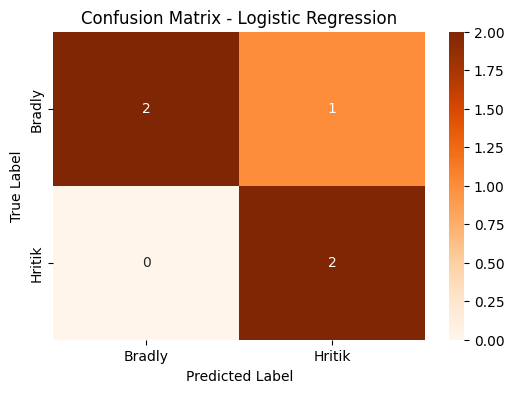

In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# 1. Scale the feature vectors
# Logistic regression performs best when pixel features are normalized/scaled
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Train the Logistic Regression Model
# We use a liblinear solver which is well-suited for smaller datasets
log_reg = LogisticRegression(max_iter=1000, random_state=42, solver='liblinear')
log_reg.fit(X_train_scaled, y_train)

# 3. Predict on the test set
y_pred_lr = log_reg.predict(X_test_scaled)

# 4. Evaluate Performance
accuracy_lr = accuracy_score(y_test, y_pred_lr)
print(f"Logistic Regression Accuracy: {accuracy_lr * 100:.2f}%\n")

print("Classification Report:")
print(classification_report(y_test, y_pred_lr))

# 5. Visualizing the Confusion Matrix
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=categories)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_lr, annot=True, fmt='d', xticklabels=categories, yticklabels=categories, cmap='Oranges')
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

Found 1 misclassified image(s) in the test set.



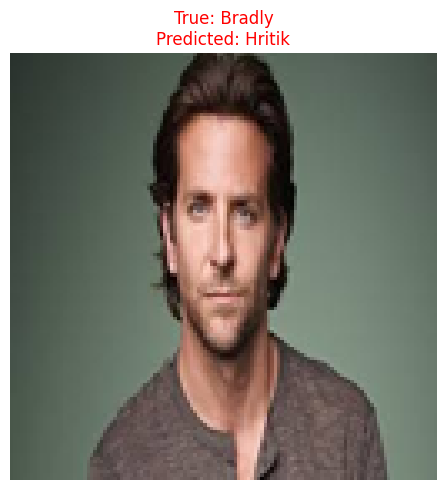

In [31]:
import numpy as np

# 1. Identify indices where the prediction does not match the actual label
misclassified_indices = np.where(y_pred_lr != y_test)[0]

if len(misclassified_indices) == 0:
    print("No misclassified images found in the test set!")
else:
    print(f"Found {len(misclassified_indices)} misclassified image(s) in the test set.\n")

    # Plot misclassified images
    plt.figure(figsize=(5 * len(misclassified_indices), 5))
    for idx, test_idx in enumerate(misclassified_indices):
        # Retrieve original pixel representation
        # Since X_test matches the split from features_df, we can locate the row index
        flat_img = X_test[test_idx]
        # Reshape the flat 49152 vector back to (128, 128, 3)
        img_rgb = flat_img.reshape((128, 128, 3))

        true_lbl = y_test[test_idx]
        pred_lbl = y_pred_lr[test_idx]

        plt.subplot(1, len(misclassified_indices), idx + 1)
        plt.imshow(img_rgb)
        plt.title(f"True: {true_lbl}\nPredicted: {pred_lbl}", color='red')
        plt.axis('off')

    plt.tight_layout()
    plt.show()

SVM Model Accuracy: 80.00%

Classification Report:
              precision    recall  f1-score   support

      Bradly       1.00      0.67      0.80         3
      Hritik       0.67      1.00      0.80         2

    accuracy                           0.80         5
   macro avg       0.83      0.83      0.80         5
weighted avg       0.87      0.80      0.80         5



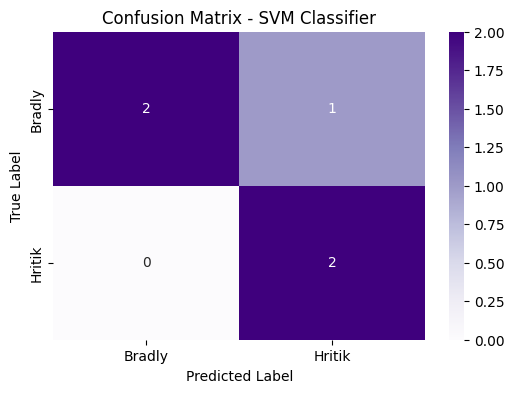

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# 1. Scale the feature vectors (if not already scaled or to ensure fresh scaling)
# We'll use the already defined X_train and X_test from previous steps.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Initialize and Train the SVM Classifier
# Using a linear kernel as a starting point, which is often efficient for high-dimensional data
svm_model = SVC(kernel='linear', random_state=42)
svm_model.fit(X_train_scaled, y_train)

# 3. Predict on the test set
y_pred_svm = svm_model.predict(X_test_scaled)

# 4. Evaluate Performance
accuracy_svm = accuracy_score(y_test, y_pred_svm)
print(f"SVM Model Accuracy: {accuracy_svm * 100:.2f}%\n")

print("Classification Report:")
print(classification_report(y_test, y_pred_svm))

# 5. Visualizing the Confusion Matrix
cm_svm = confusion_matrix(y_test, y_pred_svm, labels=categories)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_svm, annot=True, fmt='d', xticklabels=categories, yticklabels=categories, cmap='Purples')
plt.title('Confusion Matrix - SVM Classifier')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

Found 1 misclassified image(s) by SVM in the test set.



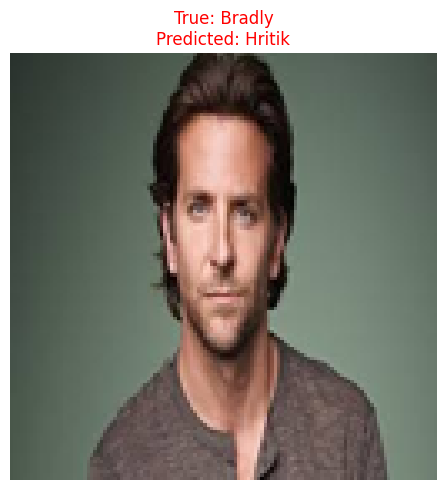

In [38]:
import numpy as np

# 1. Identify indices where the SVM prediction does not match the actual label
misclassified_indices_svm = np.where(y_pred_svm != y_test)[0]

if len(misclassified_indices_svm) == 0:
    print("No misclassified images found by the SVM model in the test set!")
else:
    print(f"Found {len(misclassified_indices_svm)} misclassified image(s) by SVM in the test set.\n")

    # Plot misclassified images
    plt.figure(figsize=(5 * len(misclassified_indices_svm), 5))
    for idx, test_idx in enumerate(misclassified_indices_svm):
        # Retrieve original pixel representation from X_test (unscaled)
        flat_img = X_test[test_idx]
        # Reshape the flat vector back to (128, 128, 3)
        img_rgb = flat_img.reshape((img_size[0], img_size[1], 3))

        true_lbl = y_test[test_idx]
        pred_lbl = y_pred_svm[test_idx]

        plt.subplot(1, len(misclassified_indices_svm), idx + 1)
        plt.imshow(img_rgb)
        plt.title(f"True: {true_lbl}\nPredicted: {pred_lbl}", color='red')
        plt.axis('off')

    plt.tight_layout()
    plt.show()

Found 2 misclassified image(s) by KNN in the test set.



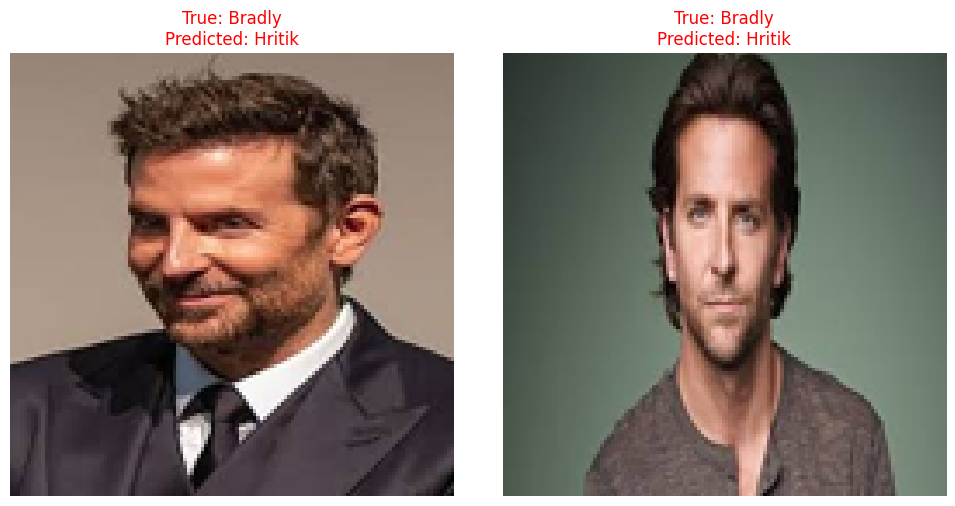

In [39]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Identify indices where the KNN prediction does not match the actual label
misclassified_indices_knn = np.where(y_pred != y_test)[0]

if len(misclassified_indices_knn) == 0:
    print("No misclassified images found by the KNN model in the test set!")
else:
    print(f"Found {len(misclassified_indices_knn)} misclassified image(s) by KNN in the test set.\n")

    # Plot misclassified images for KNN
    plt.figure(figsize=(5 * len(misclassified_indices_knn), 5))
    for idx, test_idx in enumerate(misclassified_indices_knn):
        # Retrieve original pixel representation from X_test (unscaled)
        flat_img = X_test[test_idx]
        # Reshape the flat vector back to (128, 128, 3)
        img_rgb = flat_img.reshape((img_size[0], img_size[1], 3))

        true_lbl = y_test[test_idx]
        pred_lbl = y_pred[test_idx]

        plt.subplot(1, len(misclassified_indices_knn), idx + 1)
        plt.imshow(img_rgb)
        plt.title(f"True: {true_lbl}\nPredicted: {pred_lbl}", color='red')
        plt.axis('off')

    plt.tight_layout()
    plt.show()

### Side-by-Side Comparison of Misclassified Images (KNN vs. SVM)

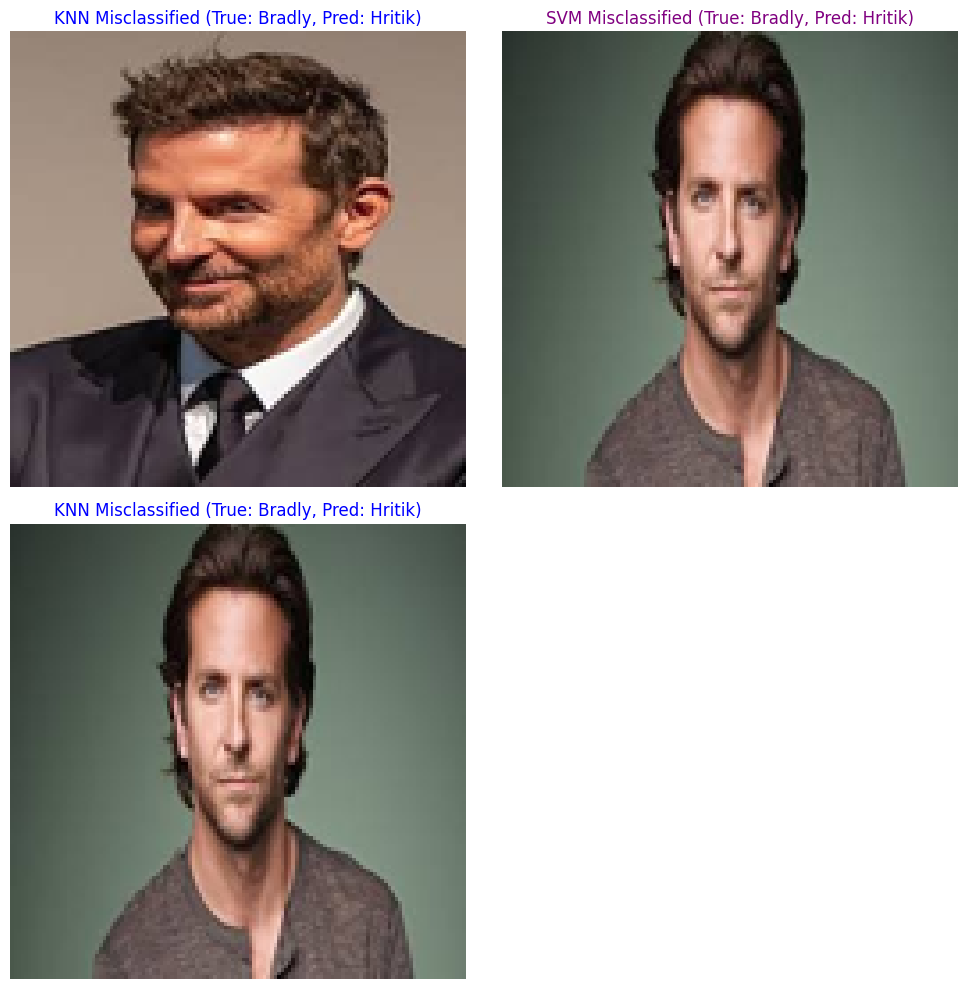

In [40]:
import numpy as np
import matplotlib.pyplot as plt

# Determine the maximum number of misclassified images to display
max_misclassified = max(len(misclassified_indices_knn), len(misclassified_indices_svm))

if max_misclassified == 0:
    print("No misclassified images for either KNN or SVM to compare.")
else:
    fig, axes = plt.subplots(max_misclassified, 2, figsize=(10, 5 * max_misclassified))

    if max_misclassified == 1: # Handle single misclassification case for proper indexing
        axes = np.expand_dims(axes, axis=0)

    # Plot KNN misclassifications
    for i, test_idx in enumerate(misclassified_indices_knn):
        flat_img = X_test[test_idx]
        img_rgb = flat_img.reshape((img_size[0], img_size[1], 3))
        true_lbl = y_test[test_idx]
        pred_lbl = y_pred[test_idx]

        axes[i, 0].imshow(img_rgb)
        axes[i, 0].set_title(f"KNN Misclassified (True: {true_lbl}, Pred: {pred_lbl})", color='blue')
        axes[i, 0].axis('off')

    # Plot SVM misclassifications
    for i, test_idx in enumerate(misclassified_indices_svm):
        flat_img = X_test[test_idx]
        img_rgb = flat_img.reshape((img_size[0], img_size[1], 3))
        true_lbl = y_test[test_idx]
        pred_lbl = y_pred_svm[test_idx]

        axes[i, 1].imshow(img_rgb)
        axes[i, 1].set_title(f"SVM Misclassified (True: {true_lbl}, Pred: {pred_lbl})", color='purple')
        axes[i, 1].axis('off')

    # Hide unused subplots if one model has fewer misclassifications
    for i in range(len(misclassified_indices_knn), max_misclassified):
        fig.delaxes(axes[i, 0])
    for i in range(len(misclassified_indices_svm), max_misclassified):
        fig.delaxes(axes[i, 1])

    plt.tight_layout()
    plt.show()

## PyTorch CNN Implementation

Now, let's implement a Convolutional Neural Network using PyTorch. This will involve several steps:
1.  **Data Preparation**: Convert NumPy arrays to PyTorch tensors and create `Dataset` and `DataLoader` objects.
2.  **Model Definition**: Define the CNN architecture using `torch.nn.Module`.
3.  **Training Loop**: Implement the training and validation process.
4.  **Evaluation**: Assess the model's performance on the test set.

In [44]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Convert NumPy arrays to PyTorch Tensors
# X_train_cnn, X_test_cnn are already normalized (0-1) float32 arrays from previous Keras preprocessing
# y_train_encoded, y_test_encoded are 0/1 integer labels

X_train_tensor = torch.tensor(X_train_cnn, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_cnn, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_encoded, dtype=torch.float32).unsqueeze(1) # Add channel dimension for binary classification
y_test_tensor = torch.tensor(y_test_encoded, dtype=torch.float32).unsqueeze(1)

# 2. Create PyTorch Dataset and DataLoader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

BATCH_SIZE = 8 # Given the small dataset, a small batch size is appropriate
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("PyTorch data preparation complete.")
print(f"X_train_tensor shape: {X_train_tensor.shape}")
print(f"y_train_tensor shape: {y_train_tensor.shape}")

PyTorch data preparation complete.
X_train_tensor shape: torch.Size([15, 128, 128, 3])
y_train_tensor shape: torch.Size([15, 1])


In [52]:
class SimpleCNN6Layers(nn.Module):
    def __init__(self, num_classes=1):
        super(SimpleCNN6Layers, self).__init__()
        # Exact 6 operational layers defined sequentially:
        # 1. Conv2d
        # 2. ReLU
        # 3. MaxPool2d
        # 4. Conv2d
        # 5. ReLU
        # 6. Linear (Classifier)

        self.layer1 = nn.Conv2d(3, 16, kernel_size=3, padding=1) # Layer 1
        self.layer2 = nn.ReLU()                                   # Layer 2
        self.layer3 = nn.MaxPool2d(kernel_size=2, stride=2)       # Layer 3
        self.layer4 = nn.Conv2d(16, 32, kernel_size=3, padding=1) # Layer 4
        self.layer5 = nn.ReLU()                                   # Layer 5

        # Calculate flattened features after MaxPool (128x128 -> 64x64)
        # 64 * 64 * 32 = 131072
        self.layer6 = nn.Linear(32 * 64 * 64, num_classes)        # Layer 6

    def forward(self, x):
        out = self.layer1(x)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.layer4(out)
        out = self.layer5(out)
        out = out.view(out.size(0), -1) # Flatten
        out = self.layer6(out)
        return out

# Instantiate the 6-layer model
pytorch_cnn_model = SimpleCNN6Layers()
pytorch_cnn_model.to(device)
print("PyTorch 6-Layer CNN model defined.")
print(pytorch_cnn_model)

PyTorch 6-Layer CNN model defined.
SimpleCNN6Layers(
  (layer1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (layer2): ReLU()
  (layer3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (layer4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (layer5): ReLU()
  (layer6): Linear(in_features=131072, out_features=1, bias=True)
)


In [53]:
# 3. Define the PyTorch CNN Model
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=1):
        super(SimpleCNN, self).__init__()
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), # Input: 3 channels (RGB)
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Calculate flattened features after conv layers for the first batch
        # A common way is to pass a dummy tensor to get its shape
        dummy_input = torch.zeros(1, 3, img_size[0], img_size[1])
        flattened_size = self._get_conv_output_size(dummy_input)

        self.fc_layers = nn.Sequential(
            nn.Linear(flattened_size, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes) # num_classes=1 for binary classification with sigmoid
        )

    def _get_conv_output_size(self, x):
        output = self.conv_layers(x)
        return int(np.prod(output.size()))

    def forward(self, x):
        x = self.conv_layers(x)
        x = x.view(x.size(0), -1) # Flatten the tensor
        x = self.fc_layers(x)
        return x

# Instantiate the model
pytorch_cnn_model = SimpleCNN()

# Move model to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pytorch_cnn_model.to(device)

print("PyTorch CNN model defined.")
print(pytorch_cnn_model)

PyTorch CNN model defined.
SimpleCNN(
  (conv_layers): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc_layers): Sequential(
    (0): Linear(in_features=16384, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)


### Training the PyTorch CNN Model

Now we will define the loss function, optimizer, and implement the training loop for our PyTorch CNN model. We will train for a few epochs and monitor both training and validation performance.

In [54]:
# 4. Define Loss Function and Optimizer
criterion = nn.BCEWithLogitsLoss() # For binary classification, combines sigmoid and BCELoss
optimizer = optim.Adam(pytorch_cnn_model.parameters(), lr=0.001)

# 5. Training Loop
NUM_EPOCHS = 20 # Adjust as needed

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(NUM_EPOCHS):
    pytorch_cnn_model.train() # Set model to training mode
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for inputs, labels in train_loader:
        # Permute and make contiguous to avoid PyTorch stride view/reshape errors
        inputs = inputs.permute(0, 3, 1, 2).contiguous()
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad() # Zero the parameter gradients

        outputs = pytorch_cnn_model(inputs)
        loss = criterion(outputs, labels)
        loss.backward() # Backpropagation
        optimizer.step() # Update weights

        running_loss += loss.item() * inputs.size(0)

        # Calculate training accuracy
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / len(train_dataset)
    epoch_train_acc = correct_train / total_train
    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)

    # Validation phase
    pytorch_cnn_model.eval() # Set model to evaluation mode
    val_loss = 0.0
    correct_val = 0
    total_val = 0
    with torch.no_grad(): # No need to compute gradients during validation
        for inputs, labels in test_loader:
            inputs = inputs.permute(0, 3, 1, 2).contiguous()
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = pytorch_cnn_model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)

            predicted = (torch.sigmoid(outputs) > 0.5).float()
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    epoch_val_loss = val_loss / len(test_dataset)
    epoch_val_acc = correct_val / total_val
    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)

    print(f'Epoch {epoch+1}/{NUM_EPOCHS}, Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.4f}, '+
          f'Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.4f}')

print("\nPyTorch CNN Training complete.")

Epoch 1/20, Train Loss: 0.8344, Train Acc: 0.4000, Val Loss: 0.7003, Val Acc: 0.4000
Epoch 2/20, Train Loss: 0.6743, Train Acc: 0.6000, Val Loss: 0.6839, Val Acc: 0.6000
Epoch 3/20, Train Loss: 0.6964, Train Acc: 0.4667, Val Loss: 0.6836, Val Acc: 0.6000
Epoch 4/20, Train Loss: 0.6787, Train Acc: 0.6000, Val Loss: 0.7027, Val Acc: 0.4000
Epoch 5/20, Train Loss: 0.6475, Train Acc: 0.5333, Val Loss: 0.7032, Val Acc: 0.4000
Epoch 6/20, Train Loss: 0.6210, Train Acc: 0.6667, Val Loss: 0.6738, Val Acc: 0.6000
Epoch 7/20, Train Loss: 0.5408, Train Acc: 0.8667, Val Loss: 0.6626, Val Acc: 0.6000
Epoch 8/20, Train Loss: 0.4406, Train Acc: 0.9333, Val Loss: 0.6594, Val Acc: 0.6000
Epoch 9/20, Train Loss: 0.3782, Train Acc: 0.8000, Val Loss: 0.6196, Val Acc: 0.8000
Epoch 10/20, Train Loss: 0.2263, Train Acc: 0.9333, Val Loss: 0.7828, Val Acc: 0.6000
Epoch 11/20, Train Loss: 0.1565, Train Acc: 1.0000, Val Loss: 0.6312, Val Acc: 0.6000
Epoch 12/20, Train Loss: 0.3675, Train Acc: 0.9333, Val Loss: 0

### Evaluating the PyTorch CNN Model

Now, let's evaluate the performance of our trained PyTorch CNN model on the test set. We'll generate a classification report and a confusion matrix to get a detailed view of its accuracy, precision, recall, and F1-score.

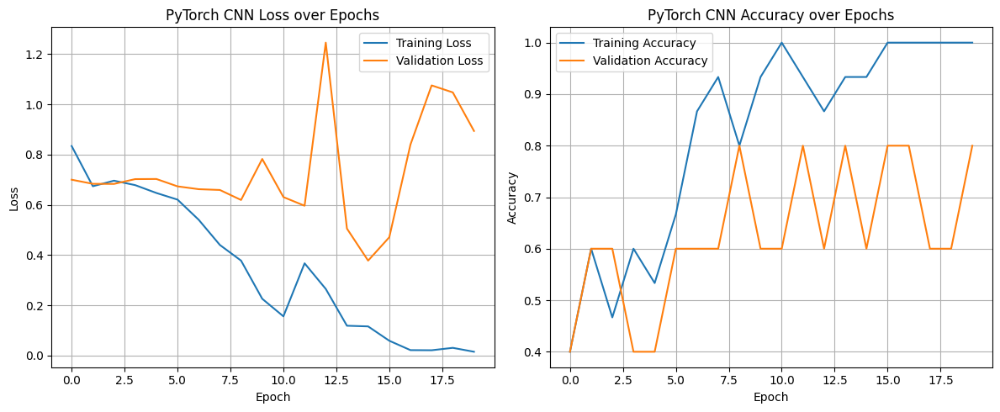


PyTorch CNN Test Accuracy: 80.00%

Classification Report (PyTorch CNN):
              precision    recall  f1-score   support

      Bradly       1.00      0.67      0.80         3
      Hritik       0.67      1.00      0.80         2

    accuracy                           0.80         5
   macro avg       0.83      0.83      0.80         5
weighted avg       0.87      0.80      0.80         5



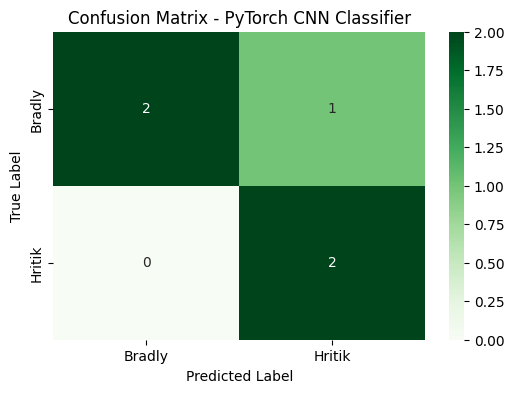

In [55]:
import matplotlib.pyplot as plt

# Plot training and validation loss
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('PyTorch CNN Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot training and validation accuracy
plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='Training Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('PyTorch CNN Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# Make predictions on the test set
pytorch_cnn_model.eval()
all_predictions = []
all_true_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:
        # Permute and make contiguous to match (Batch, Channels, Height, Width)
        inputs = inputs.permute(0, 3, 1, 2).contiguous()
        inputs = inputs.to(device)
        outputs = pytorch_cnn_model(inputs)
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        all_predictions.extend(predicted.cpu().numpy())
        all_true_labels.extend(labels.cpu().numpy())

# Convert to numpy arrays
all_predictions = np.array(all_predictions).flatten()
all_true_labels = np.array(all_true_labels).flatten()

# Map numerical labels back to original category names for reporting
predicted_labels_str = label_encoder.inverse_transform(all_predictions.astype(int))
true_labels_str = label_encoder.inverse_transform(all_true_labels.astype(int))

# Evaluate performance
accuracy_pytorch_cnn = accuracy_score(true_labels_str, predicted_labels_str)
print(f"\nPyTorch CNN Test Accuracy: {accuracy_pytorch_cnn * 100:.2f}%")

print("\nClassification Report (PyTorch CNN):")
print(classification_report(true_labels_str, predicted_labels_str))

# Plot Confusion Matrix
cm_pytorch_cnn = confusion_matrix(true_labels_str, predicted_labels_str, labels=categories)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_pytorch_cnn, annot=True, fmt='d', xticklabels=categories, yticklabels=categories, cmap='Greens')
plt.title('Confusion Matrix - PyTorch CNN Classifier')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()